# 🛍️ E-commerce Spending Prediction Model

**Author:** Tusnelde Endjala  
**Date:** October 2026  
**Tools:** Python · Pandas · Seaborn · Matplotlib · Scikit-learn

---

## 📌 Project Overview

This notebook builds a **Multiple Linear Regression** model to predict the **Yearly Amount Spent** by customers of an e-commerce clothing retailer.

The business offers in-person styling appointments; customers then complete purchases via either a **mobile app or a **website**. The goal is to:

1. Understand which platform (appvs. website) has a stronger relationship with annual spending
2. Identity the most important drivers of customer revenue
3. Build a reliable predictive model that can inform digital investment strategy

---
## 📂 Dataset

**File:** `ecommerce.csv`  
**Features used in the model:**

| Feature | Description |
|---|---|
| `Avg. Session Length` | Average duration of in-store styling sessions (minutes) |
| `Time on App` | Average monthly time spent on the mobile application (minutes) |
| `Time on Website` | Average monthly time spent on the desktop website (minutes) |
| `Length of Membership` | Number of years the customer has been a member |
| `Yearly Amount Spent` | **Target variable** — total annual spend (USD) |

---

## 🗂️ Notebook Structure
    
1. [Library Imports & Data Loading](#1)
2. [Exploratory Data Analysis (EDA)](#2)
3. [Feature Selection & Train/Test Split](#3)
4. [Model Training](#4)
5. [Predictions & Visual Evaluation](#5)
6. [Error Metrics](#6)
7. [Residual Analysis](#7)

---

## 1. Library Imports & Data Loading

Import the core libraries required for data manipulation, visualisation, and machine learning.

In [6]:
# mporting libraries
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

Load the dataset from the csv file into a pandas DataFrame for exploration

In [7]:
df = pd.read_csv("ecommerce.csv")

### Initial Data Inspection

Preview the first five rows to confirm the dataset loaded correctly and inspect the feature structure.

In [8]:
df.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


Checks the data types, column names, and whether any null values are present.
A clean dataset with no missing values allows me to proceed directly to analysis.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


 ## 2. Exploratory Data Analysis (EDA)

Before building a model, I explore the relationships between each feature and the target variable ('Yearly Amount Spent').
This step helps me understand which features are likely to be strong predictors and flags any non-linear relationships that may affect model assumptions.

## 2.1 Website Engagement vs Annual Spend

A joint plot shows the marginal distributions (histograms) alongside the scatter plot, giving me a combined view of the distribution and the correlation. 

# Exploratory Data Analysis

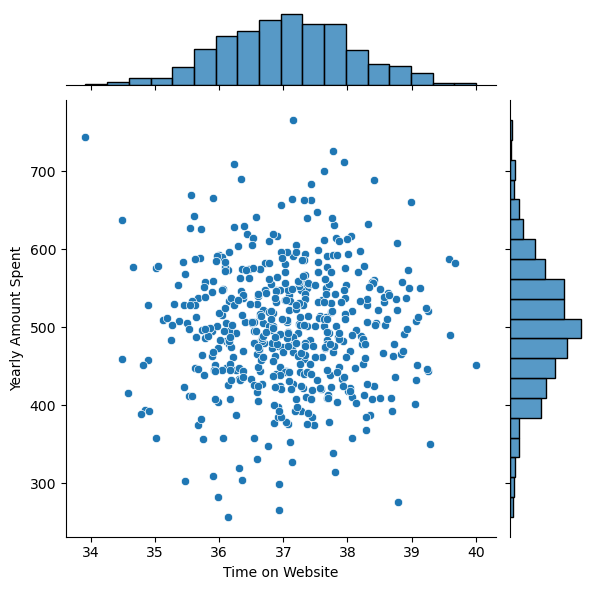

In [10]:
## time on website vs yearly amount spent
sns.jointplot(x="Time on Website", y="Yearly Amount Spent", data=df)
plt.show()

Generate a statistical summary of all numerical columns - including count, mean, standard deviation, and quartile values.
This confirms the scale of the features and helps detect any outliers.

In [11]:
 df.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


Re-plot the Website vs Spend joint plot with alpha=0.5 to reduce overplotting and reveal the true density of the data points.

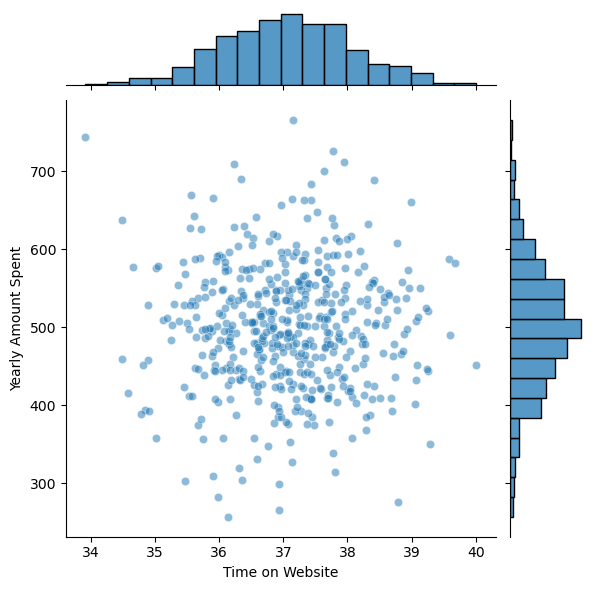

In [12]:
#passsing a parameter of alpha
sns.jointplot(x="Time on Website", y="Yearly Amount Spent", data=df, alpha=0.5)
plt.show()

2.2 App Engagement vs Annual Spend

Compare the app's relationship with annual spend.
I expected a stronger positive correlation here compared to the website.

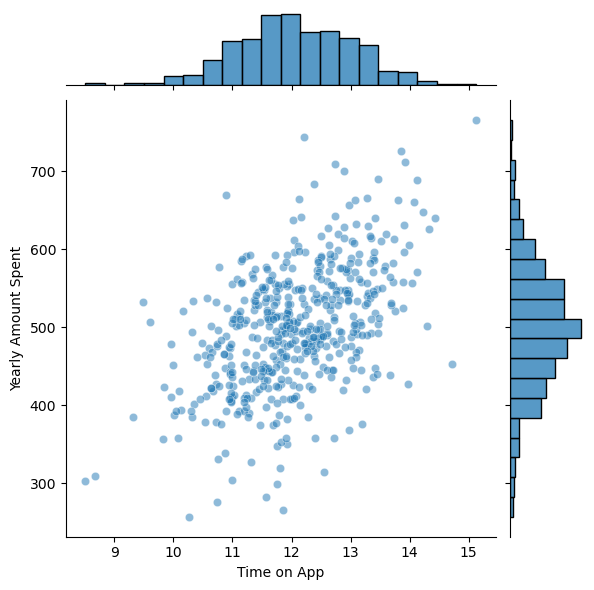

In [13]:

# time on app vs yearly amount spent
sns.jointplot(x='Time on App', y='Yearly Amount Spent', data= df, alpha=0.5)
plt.show()

### 2.3 Pairplot - All Feature Relationships

A pairplot visualises the relationships between **every pair of numerical variables** simultaneously.
This is one of the most effective EDA tools for identifying which features correlate strongly with the target and dectecting multicollinearity between predictors.

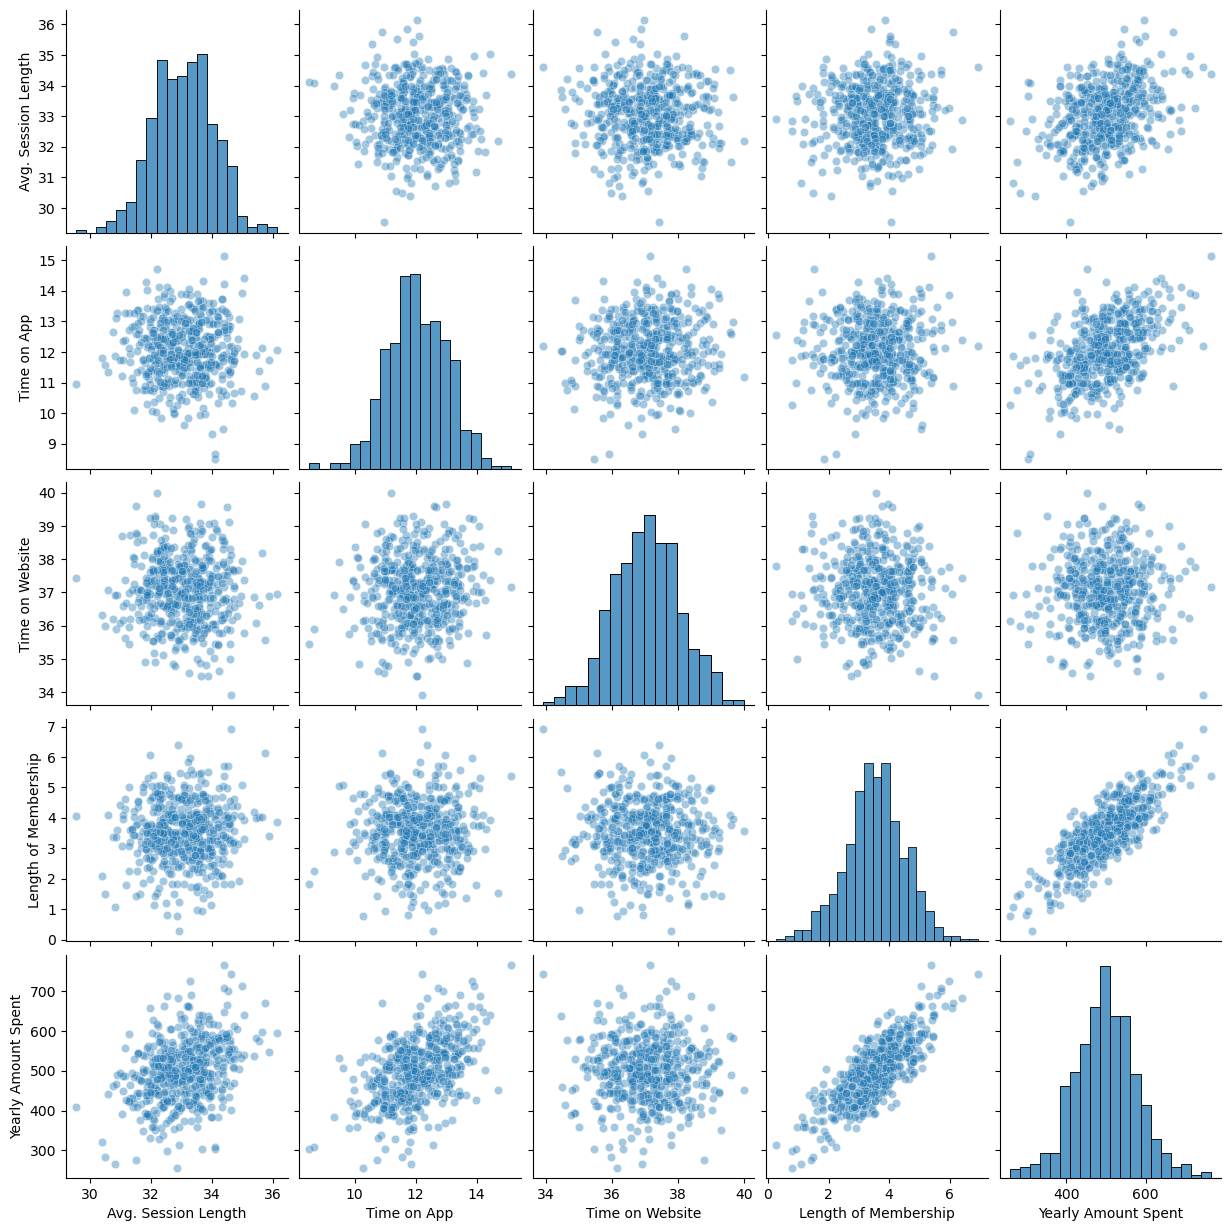

In [14]:
#Pairplot
sns.pairplot(df, kind='scatter', plot_kws={'alpha': 0.4})
plt.show()

Re-examine the App vs Spend relationship in isolation. Confirming a clear positive trend validates that `Time on App` is a meaningful predictor to include in the regression model. 

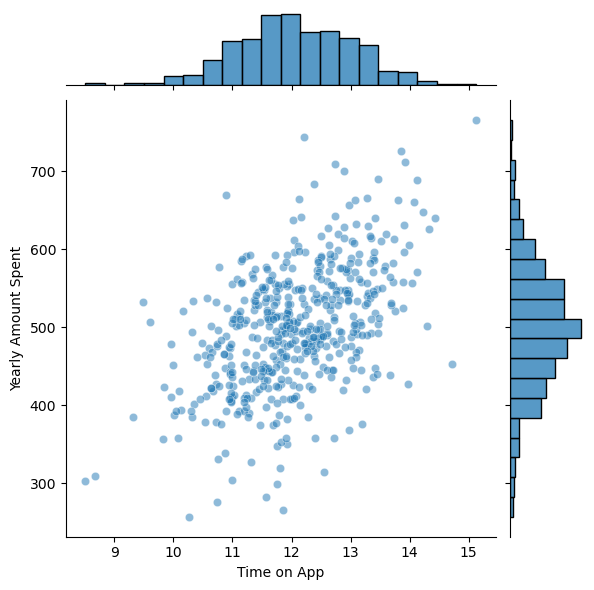

In [15]:
# # time on app vs yearly amount spent
sns.jointplot(x="Time on App", y="Yearly Amount Spent", data=df, alpha=0.5)
plt.show()

### 2.4 Length of Membership vs Annual Spend 

Using a linear model plot (`lmplot`) with a fitted regression line to visualise the relationship between membership duration and yearly spend.
This is expected to be the single strongest predictor in the model based on the pairplot.

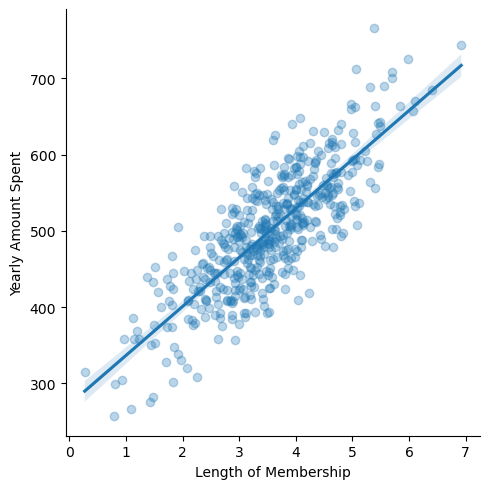

In [16]:
sns.lmplot(x = 'Length of Membership', 
           y = 'Yearly Amount Spent',
           data = df,
           scatter_kws={'alpha': 0.3})
plt.show()

## 3. Feature Selection & Train/Test Split

### 3.1 Importing the Splitting Utility

Import `train_test_split` from scikit-learn to divide the data into independent training and testing subsets.

In [17]:
from sklearn.model_selection import train_test_split

### 3.2 Initial Feature Exploration (Two Variables)

Before building the full model, I first inspect the feature matrix using only two variables  - `Time on App` and `Time on Website` - to understand the basic structure of `X`.

In [18]:
X = df[['Time on App', 'Time on Website']]
X  

,Time on App,Time on Website
0,12.655651,39.577668
1,11.109461,37.268959
2,11.330278,37.110597
3,13.717514,36.721283
4,12.795189,37.536653
...,...,...
495,13.566160,36.417985
496,11.695736,37.190268
497,11.499409,38.332576
498,12.391423,36.840086


### 3.3 Final Feature Matrix 

Expand `X` to include all four predictors. `y` is set to the target variable `Yearly Amount Spend`.

In [19]:
#create multiple variable
X = df[['Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership']]
y = df['Yearly Amount Spent'] 

### 3.4 Train/Test Split

Split the dataset into **70% training** and **30% testing** subsets using `random_state=42` for reproducibility.
The training set is used to fit the model; the test set is held out to evaluate how well the model generalises to unseen data.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

Inspect the training and testing subsets to confirm the split was applied correctly.

In [21]:
X_train

,Avg. Session Length,Time on App,Time on Website,Length of Membership
5,33.871038,12.026925,34.476878,5.493507
116,33.925795,12.011022,36.701052,2.753424
45,34.555768,12.170525,39.131097,3.663105
16,32.125387,11.733862,34.894093,3.136133
462,33.503810,11.233415,37.211153,2.320550
...,...,...,...,...
106,32.291756,12.190474,36.152462,3.781823
270,34.006489,12.956277,38.655095,3.275734
348,31.812483,10.886921,34.897828,3.128639
435,32.259973,14.132893,37.023479,3.762070


In [22]:
X_test

,Avg. Session Length,Time on App,Time on Website,Length of Membership
361,32.077590,10.347877,39.045156,3.434560
73,32.808698,12.817113,37.031539,3.851579
374,31.447446,10.101632,38.043453,4.238296
155,32.449522,13.457725,37.238806,2.941411
104,31.389585,10.994224,38.074452,3.428860
...,...,...,...,...
266,34.555283,11.777772,37.979827,3.784273
23,32.903251,11.657576,36.772604,3.919302
222,34.334865,11.109456,38.585855,3.892891
261,32.550527,13.041245,36.655208,3.456234


In [23]:
y_test

361    401.033135
73     534.777188
374    418.602742
155    503.978379
104    410.069611
          ...    
266    554.003093
23     519.340989
222    502.409785
261    514.009818
426    530.766719
Name: Yearly Amount Spent, Length: 150, dtype: float64

In [24]:
y_train

5      637.102448
116    479.231093
45     549.860590
16     457.847696
462    397.420584
          ...    
106    494.551861
270    540.995739
348    392.810345
435    571.216005
102    420.737673
Name: Yearly Amount Spent, Length: 350, dtype: float64

---

## 4. Model Training

### 4.1 Importing the Model

Import `LinearRegression` from scikit-learn's `linear_model` module.

In [25]:
#training the model
from sklearn.linear_model import LinearRegression

### 4.2 Instantiate the Model

Create an instance of the `LinearRegression` estimator. No hyperparameter tuning is required for OLS linear regression.

In [26]:
#Calling the model
lm = LinearRegression()

### 4.3 Fit the Model 

Train the model on the training data. The `fit()` method estimates the optimal regression coefficients (β values) that minimise the sum of squared residuals between presicted and actual values.

In [27]:
lm.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### 4.4 Model Coefficients

Inspect the raw coefficient array returned by the fitted model.
Each value represent the change in `Yearly Amount Spent` for a one-unit increase in the corresponding feature, holding all other features constant.

In [28]:
lm.coef_

array([25.72425621, 38.59713548,  0.45914788, 61.67473243])

Display the coefficients in a labelled DataFrame for clarity.
A higher absolute coefficient indicates a stronger influence on annual spending.
This table forms the basis of my **feature importance ranking** and the strategic recommendation for mobile app vs. website investment.

In [29]:
cdf = pd.DataFrame(lm.coef_, X.columns, columns=['coef'])
print(cdf)

                           coef
Avg. Session Length   25.724256
Time on App           38.597135
Time on Website        0.459148
Length of Membership  61.674732


---

## 5. Prediction & Visual Evaluation

Use the trained model to generate spending predictions on the held-out test set.

# prediction

In [30]:
predictions = lm.predict(X_test)

Preview the raw prediction values generated by the model for the test set customers

In [31]:
predictions

array([403.66993069, 542.57756289, 427.06591658, 502.02460425,
       410.12143559, 569.93442508, 531.93431341, 506.29650969,
       408.71870658, 473.97737105, 441.46912726, 425.33703059,
       425.1297229 , 527.61676714, 431.45684016, 424.0769184 ,
       575.76543296, 484.89856554, 458.35936863, 481.96502182,
       502.32441491, 513.63783554, 507.58877002, 646.57464283,
       450.24372141, 496.27043415, 556.40457807, 554.95630839,
       399.64237199, 325.84623136, 532.89783259, 478.12238702,
       501.05701845, 305.97335848, 505.77244448, 483.79591969,
       518.8331528 , 438.18241857, 456.71094234, 471.04609461,
       494.44008972, 445.31155755, 508.78802753, 501.04594193,
       488.83499673, 535.38079541, 595.20129802, 514.04714872,
       280.76758312, 433.10112367, 421.70823427, 481.23640152,
       584.71372272, 608.7748096 , 563.98513427, 494.72804869,
       394.52133407, 456.4197529 , 573.08767515, 499.6984241 ,
       512.83277025, 392.12434043, 480.05057697, 481.54

### Predicted vs Actual Scatter Plot

Plot predicted values against actual values. Points close to the diagonal line  (y = X) indicate accurate predictions.
A tight cluster along the diagonal confirms the model is performing well across the spending range.

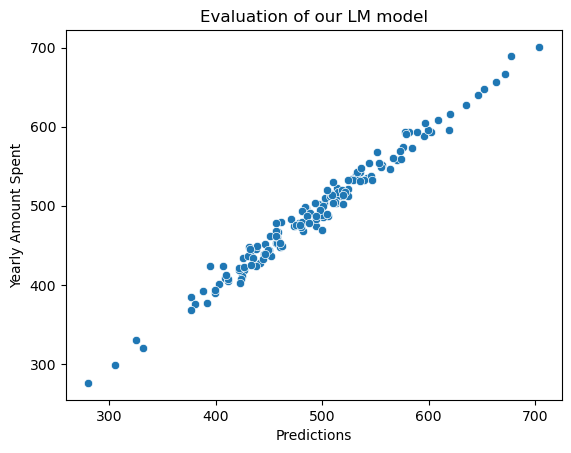

In [32]:
sns.scatterplot(x=predictions, y=y_test)
plt.xlabel("Predictions")
plt.title("Evaluation of our LM model")
plt.show()

---

## 6. Error Metrics

Import the evaluation metrics from scikit-learn to quantify model performance.

In [33]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math

### Model Evaluation

Calculate and print three complementary error metrics:

| Metric | Interpretation |
|---|---|
| **MAE** (Mean Absolute Error) | Average prediction error in USD - easy to interpret in business terms |
| **MSE** (Mean Squared Error) | Penalises larger errors more heavily than MAE |
| **RMSE** (Root Mean Squared Error) | Same unit as the target (USD) - most directly comparable to MAE |

Lower values across all three metrics indicate a more accurate model.

In [34]:
print("Means Absolute Error: ", mean_absolute_error(y_test, predictions))
print("Means Squared Error: ", mean_squared_error(y_test, predictions))
print("RMSE: ", math.sqrt(mean_squared_error(y_test, predictions)))

Means Absolute Error:  8.426091641432105
Means Squared Error:  103.91554136503315
RMSE:  10.193897260863146


---

## 7. Residuals Analysis

Residuals are the differences between the actual and predicted values: `residuals = y_test - predictions'.

**Why this matters:** A well-specified linear regression model should produce residuals that are: 
- Approximately **normally distributed** (bell-shaped, centred at zero)
- **Homoscendastic** (constant variance across prediction range)

If the residuals are non-normal or show patterns, it may indicate that the linear model is misspecified or that transformations are needed.

## Residuals

Calculate the residuls by subtracting the predicted values from the actual test values.

In [35]:
residuals = y_test - predictions


preview the raw residual values.

In [36]:
residuals

361    -2.636795
73     -7.800375
374    -8.463174
155     1.953775
104    -0.051825
         ...    
266    10.327176
23     15.027984
222   -16.778237
261    -6.021734
426    -4.371832
Name: Yearly Amount Spent, Length: 150, dtype: float64

### Residual Distribution - Initial Plot

Plot the distribution of residuals. A roughly bell-shaped histogram centred near zero is the first visual check for normality.

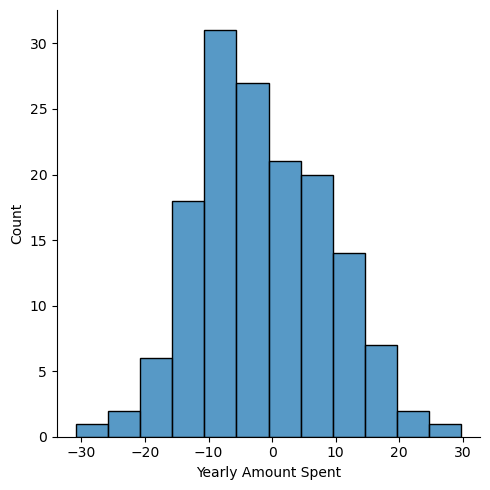

In [37]:
sns.displot(residuals)
plt.show()

Re-plot with `bins=20` for a more granular view of the residual distribution shape.

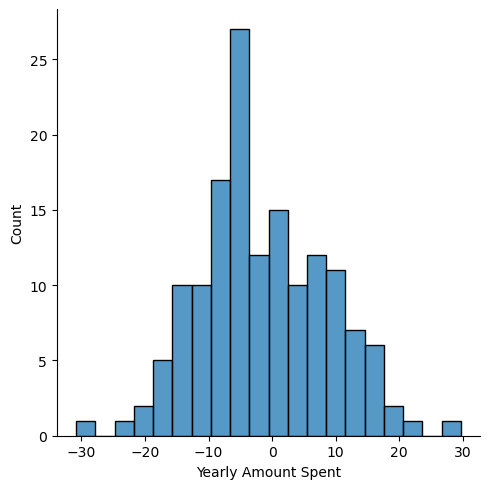

In [38]:
sns.displot(residuals, bins=20)
plt.show()

Add `kde=True` to overly a Kernel Density Estimate (KDE) curve over the histogram.
The KDE provides a smooth, continuous estimates of the underlying residual distribution - confirming whether it approximates a normal curve.

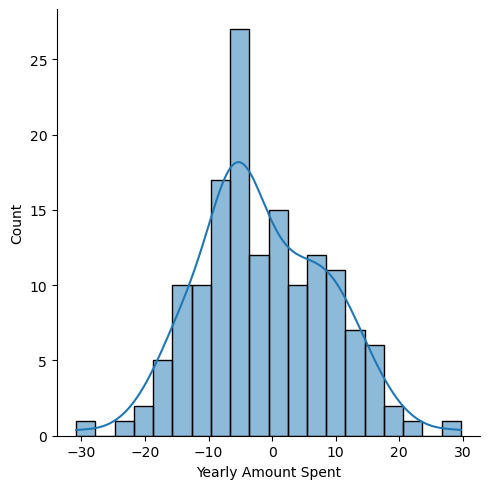

In [39]:
sns.displot(residuals, bins=20, kde=True)
plt.show()

### Q-Q Plot (Quantile-Quantile)

A Q-Q plot compares the quantiles of the residuals to the quantiles of a theoretical normal distribution.  
- **Points lying on the diagonal line** → residuals are normally distributed ✅  
- **Points deviating from the line** at the tails → heavy tails or skew in the residuals ⚠️

A good Q-Q fit here confirms that the linear regression assumptions are satisfied and that the model's error metrics are statistically valid.

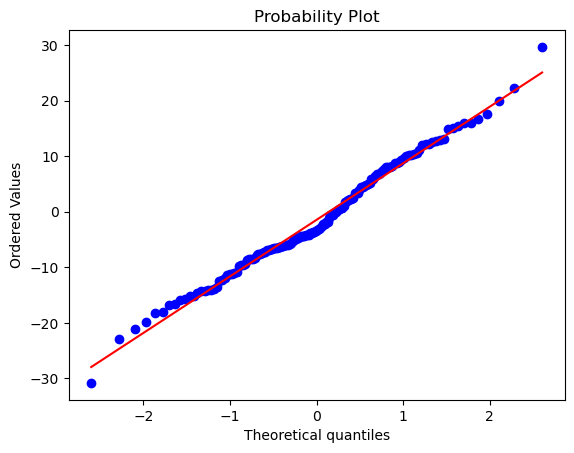

In [40]:
import pylab
import scipy.stats as stats

stats.probplot(residuals, dist="norm", plot=pylab)
pylab.show()

---

## ✅ Summary & Conclusions

### Model Results

The Multiple Linear Regression model was successfully trained and evaluated on the e-commerce customer dataset.

### Feature Importance (by Regression Coefficient)

| Rank | Feature | Direction |
|---|---|---|
| 1 | **Length of Membership** | Strong positive ↑ |
| 2 | **Time on App** | Positive ↑ |
| 3 | **Avg. Session Length** | Moderate positive ↑ |
| 4 | **Time on Website** | Low / minimal impact |

### Strategic Recommendation

- **Length of Membership** is the single strongest driver of annual spending - customer retention and loyalty programmes represent the highest-return investment.
- **Time on App** significantly outperforms **Time on Website** as a revenue driver - development resources should be directed toward the mobile application.
- The model's residuals are approximately normally distributed and the Q-Q plot confirms that linear regression assumptions are satisfied, validating the reliability of the predictions.

> This analysis provides quantitative evidence to shift the business's digital investment strategy from intuition to data-driven decision-making.